In [1]:
import numpy as np
from matplotlib import pyplot as plt

%matplotlib widget

In [25]:
import os
import skrf as rf
CWD = os.getcwd()

ntwk = rf.Network(os.path.join(CWD, r'Yao_2017\PM1_2V.s2p'))

freq = ntwk.frequency.f
s11 = ntwk.s[:,0,0]
s12 = ntwk.s[:,1,0]

eo_meas = np.loadtxt(os.path.join(CWD, r'Yao_2017\EO_data.csv'), delimiter=',')

data_eo = np.load("EO_results.npy", allow_pickle=True).item()

V = data_eo['V']
phase_change_TE_interp = data_eo['phase_change_TE_interp']

extra_phi_1 = data_eo['extra_phi_1']
extra_phi_2 = data_eo['extra_phi_2']

MZM_output_TE_interp = data_eo['MZM_output_TE_interp']
MZM_output_TE_interp10 = 10*np.log10(np.abs(1/2 * (np.exp(1j*extra_phi_2) + np.exp(1j*phase_change_TE_interp + 1j*extra_phi_1)))**2)

data_meas_TE = data_eo['data_meas_TE']

rf_data_sim = np.load(os.path.join(CWD, r'RF_data.npy'), allow_pickle=True).item()
freq_sim = rf_data_sim['freq_values']
s11_sim = rf_data_sim['S11_values']
s12_sim = rf_data_sim['S12_values']
voltage_values = rf_data_sim['voltage_values']
eo_rf_sim = rf_data_sim['EO_values']

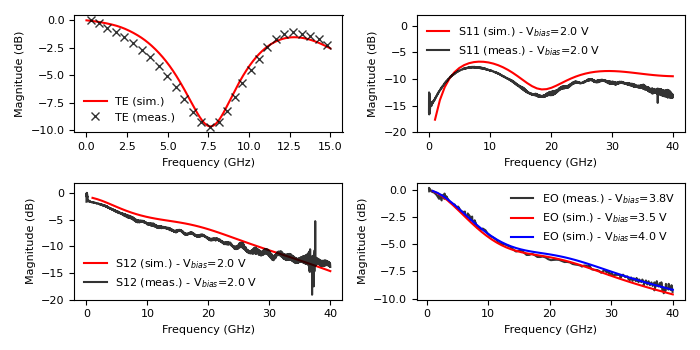

: 

In [ ]:
fig = plt.figure(figsize = (7,3.5))
gs = fig.add_gridspec(2, 2)
ax_eo = fig.add_subplot(gs[0, 0])
ax_s11 = fig.add_subplot(gs[0, 1])
ax_s12 = fig.add_subplot(gs[1, 0])
ax_eo_rf = fig.add_subplot(gs[1, 1])

color_meas = 'black'
color_sim = 'red'
alpha_meas = 0.8
ax_eo.plot(V, MZM_output_TE_interp, label='TE (sim.)', color = color_sim)
ax_eo.plot(data_meas_TE[:,0], data_meas_TE[:,1] - data_meas_TE[-1,1], 'x', label='TE (meas.)', color = color_meas, alpha = alpha_meas)
ax_eo.legend(frameon=False, loc = 'lower left', fontsize = 8)



ax_s11.plot(freq_sim, 20*np.log10(np.abs(s11_sim[0])), label=f'S11 (sim.) - V$_{{bias}}$={voltage_values[0]} V', color=color_sim)
ax_s11.plot(freq/1e9, 20*np.log10(np.abs(s11)), label='S11 (meas.) - V$_{bias}$=2.0 V', color=color_meas, alpha = alpha_meas)
ax_s11.set_ylim(-20,2)
ax_s11.legend(frameon=False, loc = 'upper left', fontsize = 8)

ax_s12.plot(freq_sim, 20*np.log10(np.abs(s12_sim[0])), label=f'S12 (sim.) - V$_{{bias}}$={voltage_values[0]} V', color=color_sim)
ax_s12.plot(freq/1e9, 20*np.log10(np.abs(s12)), label='S12 (meas.) - V$_{bias}$=2.0 V', color=color_meas, alpha = alpha_meas)
ax_s12.set_ylim(-20,2)
ax_s12.legend(frameon=False, loc = 'lower left', fontsize = 8)

i=3
ax_eo_rf.plot(eo_meas[:,0], eo_meas[:,1], label='EO (meas.) - V$_{bias}$=3.8V', color=color_meas, alpha = alpha_meas)
ax_eo_rf.plot(freq_sim, eo_rf_sim[i], label=f'EO (sim.) - V$_{{bias}}$={voltage_values[i]} V', color=color_sim)
ax_eo_rf.plot(freq_sim, eo_rf_sim[i+1], label=f'EO (sim.) - V$_{{bias}}$={voltage_values[i+1]} V', color='blue')
ax_eo_rf.legend(frameon=False, loc = 'upper right', fontsize = 8)

for ax in [ax_eo, ax_s11, ax_s12, ax_eo_rf]:
    ax.set_xlabel('Frequency (GHz)', fontsize = 8)
    ax.set_ylabel('Magnitude (dB)', fontsize = 8)
    ax.tick_params(axis='both', which='major', labelsize=8)

fig.tight_layout()

fig.savefig('EO_RF_results.png', dpi=300, bbox_inches='tight')